# RFM, PCA and behavioral cohorts

This notebook inspects the **already fitted training pipeline**. It does not refit PCA, scaling or K-Means on held-out customers. RFM describes shopping behavior; log1p + standardization makes its scales comparable; two principal components support visualization; four K-Means clusters form descriptive cohorts.

Four clusters are fixed in advance for interpretability, not selected on test outcomes or asserted to be optimal. Segment IDs are arbitrary. One-hot membership, principal coordinates and distances to centroids become XGBoost features inside every CV fold.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid", palette="colorblind")
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
import joblib
from scripts.prepare_data import FEATURES
model = joblib.load(ROOT / "models/cltv_model.joblib")
segmenter = model.pipeline_.named_steps["segments"]
customers = pd.read_csv(ROOT / "data/processed/customers.csv", index_col="CustomerID")
train = customers.loc[customers.split == "train"]
assert set(segmenter.fit_customer_ids_) == set(train.index)
coordinates = segmenter.coordinates(train[FEATURES])
labels = segmenter.segment_labels(train[FEATURES])
profiles = pd.read_csv(ROOT / "results/segment_profiles.csv", index_col="segment")

In [2]:
display(profiles)
variance = segmenter.pca_.explained_variance_ratio_
display(pd.DataFrame({"component": ["PC1", "PC2"], "explained_variance": variance}))
loadings = pd.DataFrame(segmenter.pca_.components_.T,
                        index=["log recency", "log frequency", "log monetary"],
                        columns=["PC1", "PC2"])
display(loadings)
display(Markdown(f"Fitted on **{len(train):,} training customers**; assigned "
                 f"**{len(customers):,} eligible customers** without refitting. "
                 f"Two PCs retain **{variance.sum():.1%}** of standardized log-RFM variance."))

,customers,recency_days,orders,historical_spend_gbp,tenure_days,cadence_days,profile
segment,,,,,,,
0,379,12.509028,8.0,3009.180,261.440972,28.363628,"Recent, higher value, repeat"
1,1136,154.502778,1.0,249.715,169.494444,53.068056,"Lapsed, lower value, single order"
2,749,66.412500,3.0,1085.000,212.392361,50.735417,"Recent, higher value, repeat"
3,389,16.468056,2.0,451.110,73.365972,75.023669,"Recent, lower value, repeat"


,component,explained_variance
0,PC1,0.743853
1,PC2,0.186233


,PC1,PC2
log recency,-0.516629,0.847472
log frequency,0.615176,0.268295
log monetary,0.595528,0.458048


Fitted on **2,653 training customers**; assigned **3,317 eligible customers** without refitting. Two PCs retain **93.0%** of standardized log-RFM variance.

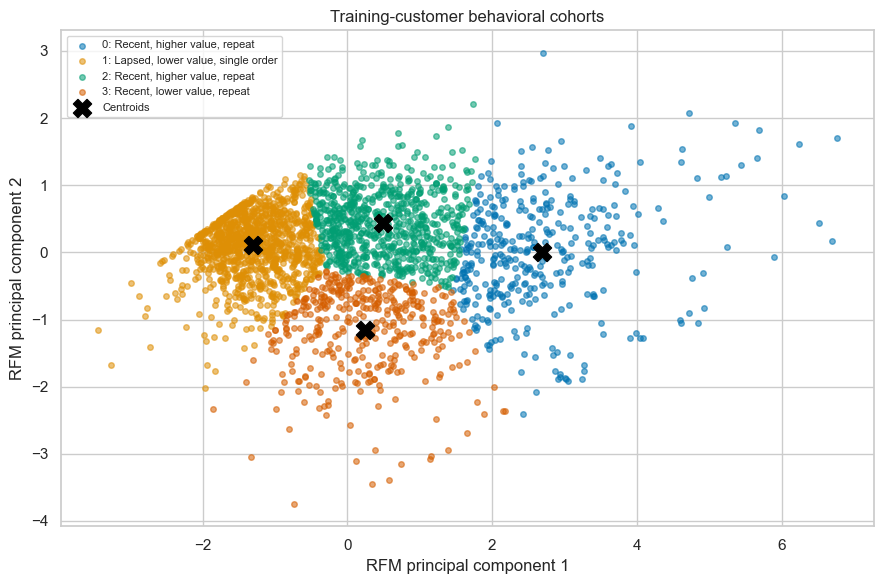

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
for segment in range(4):
    selected = labels == segment
    ax.scatter(coordinates[selected, 0], coordinates[selected, 1], s=16, alpha=.55,
               label=f"{segment}: {profiles.loc[segment, 'profile']}")
centers = segmenter.kmeans_.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], marker="X", color="black", s=170, label="Centroids")
ax.set(title="Training-customer behavioral cohorts", xlabel="RFM principal component 1",
       ylabel="RFM principal component 2")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIGURES / "pca_segments.png", dpi=150)
plt.show()

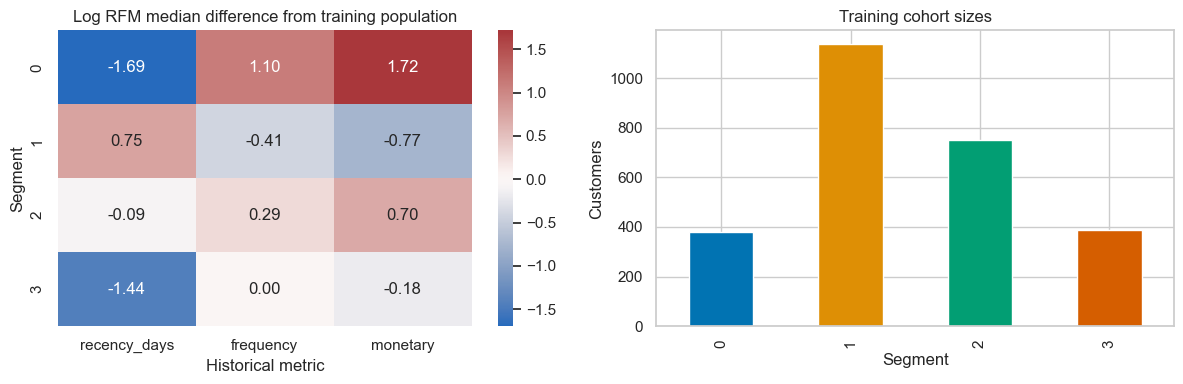

In [4]:
plot_data = train[["recency_days", "frequency", "monetary"]].copy()
plot_data["segment"] = labels
medians = plot_data.groupby("segment").median()
relative = np.log1p(medians) - np.log1p(plot_data[medians.columns].median())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(relative, annot=True, fmt=".2f", center=0, cmap="vlag", ax=axes[0])
axes[0].set(title="Log RFM median difference from training population",
            xlabel="Historical metric", ylabel="Segment")
profiles.customers.plot.bar(ax=axes[1], color=sns.color_palette("colorblind", 4))
axes[1].set(title="Training cohort sizes", xlabel="Segment", ylabel="Customers")
fig.tight_layout()
fig.savefig(FIGURES / "segment_profiles.png", dpi=150)
plt.show()

split,test,train
segment,,
0,0.135542,0.142857
1,0.411145,0.428194
2,0.305723,0.282322
3,0.147590,0.146626


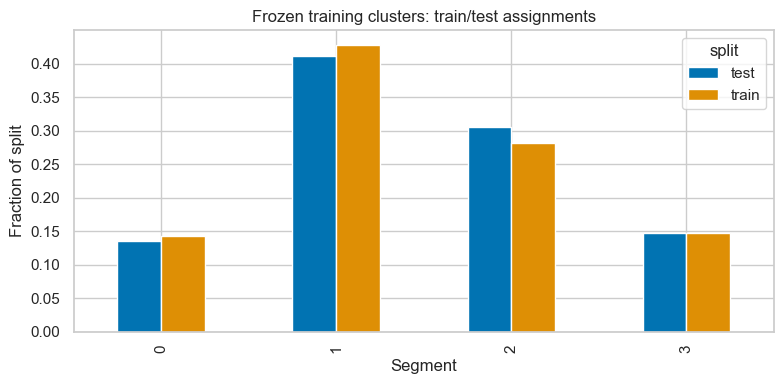

In [5]:
assigned = pd.read_csv(ROOT / "data/processed/customer_segments.csv")
proportions = pd.crosstab(assigned.segment, assigned.split, normalize="columns")
display(proportions)
fig, ax = plt.subplots(figsize=(8, 4))
proportions.plot.bar(ax=ax)
ax.set(title="Frozen training clusters: train/test assignments",
       ylabel="Fraction of split", xlabel="Segment")
fig.tight_layout()
fig.savefig(FIGURES / "segment_split_distribution.png", dpi=150)
plt.show()

In [6]:
importance = pd.read_csv(ROOT / "results/feature_importance.csv")
segment_features = importance.loc[importance.feature.str.startswith(
    ("segment_", "rfm_pc", "centroid_distance_"))]
display(segment_features)
metrics = json.loads((ROOT / "results/metrics.json").read_text())
display(pd.Series(metrics["segmentation"], name="fitted_segmentation").to_frame())
transformed = segmenter.transform(train[FEATURES])
assert transformed.shape[1] == len(segmenter.get_feature_names_out())
display(Markdown(f"**{len(FEATURES)} historical inputs** become **{transformed.shape[1]} model features**. "
                 "Imputation, log-RFM scaling, PCA and K-Means are refitted in each CV training fold."))

,feature,importance
5,centroid_distance_0,0.032096
6,rfm_pc1,0.031155
7,centroid_distance_3,0.025464
15,rfm_pc2,0.016332
17,centroid_distance_2,0.013432
18,segment_2,0.013119
20,centroid_distance_1,0.011986
21,segment_1,0.010672
27,segment_3,0.000000
28,segment_0,0.000000


,fitted_segmentation
fit_customers,2653
assigned_customers,3317
clusters,4
pca_components,2
pca_explained_variance_ratio,"[0.7438531838919618, 0.1862325375248955]"
train_silhouette_pca_space,0.431242


**19 historical inputs** become **29 model features**. Imputation, log-RFM scaling, PCA and K-Means are refitted in each CV training fold.

The generated cohort names summarize training medians only; they do not use target tiers. Recent repeat customers with high purchase value can be prioritized for account management, while lapsed single-order customers suggest a retention audience. These are descriptive hypotheses, not measured marketing treatment effects.

PCA/K-Means uses Euclidean geometry after scaling and may miss non-spherical structure. Projecting three RFM variables to two PCs loses some information; raw historical variables also remain available to XGBoost. Feature importance is descriptive split gain, not a causal effect or proof that segmentation improves accuracy. The dataset supports over 3,000 customer assignments, but the smaller training-only clustering fit must be reported separately.